# 과거 특징과 고정 Anchor

전체 원본 관측에서 과거300/900 원시단위 창을 먼저 계산합니다. 60 간격 고정 격자 Anchor에서 현재값·통계·추세를 보존하며 공백을 넘는 보간은 하지 않습니다.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert ROOT.name == 'PHM2018-Project-V2'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / 'outputs/matplotlib')
import polars as pl
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
figdir = ROOT / 'reports/figures'
figdir.mkdir(parents=True, exist_ok=True)
load = lambda name: json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))


{'A': 8, 'B': 32, 'C': 44}


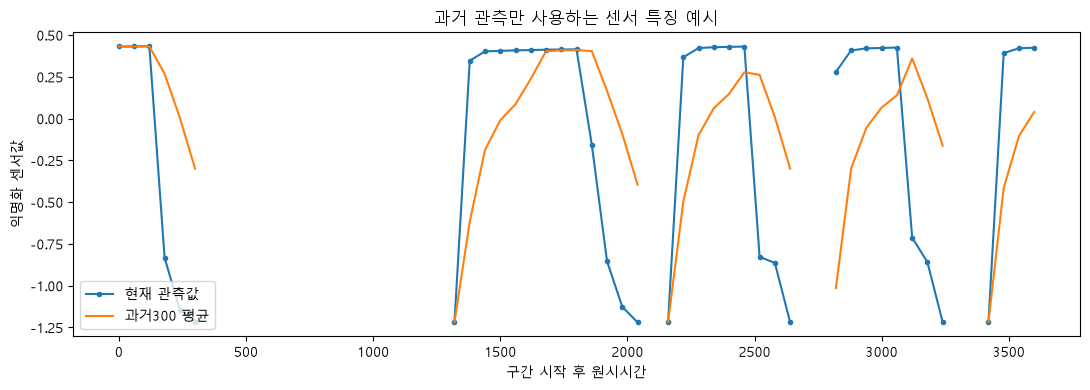

feature_status,len
str,u32
"""history_lt900""",141800
"""sensor_stale_or_gap""",452789
"""history_span_available""",67981


In [2]:
from src.features import feature_names
print({k:len(v) for k,v in feature_names().items()})
df = pl.read_parquet(ROOT / 'data/processed/diagnostic_pilot/01M01.parquet')
start = df.filter(pl.col('feature_status') == 'history_span_available')['time'][0]
part = df.filter((pl.col('time') >= start) & (pl.col('time') <= start+3600))
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(part['time']-start, part['FLOWCOOLPRESSURE'], '.-', label='현재 관측값')
ax.plot(part['time']-start, part['FLOWCOOLPRESSURE_w300_mean'], label='과거300 평균')
ax.set(xlabel='구간 시작 후 원시시간', ylabel='익명화 센서값', title='과거 관측만 사용하는 센서 특징 예시')
ax.legend(); fig.tight_layout(); fig.savefig(figdir / '03_features.png', dpi=130); plt.show()
df.group_by('feature_status').len()

## 그래프 해석과 한계

이동평균은 해당 시점까지의 원본 관측만 사용합니다. 결측/이력 부족 Anchor도 유지합니다. 그래프가 매끄럽다는 사실은 조기 예측 가능성이나 센서 물리 단위의 검증이 아닙니다. 특징 A/B/C는 8/32/44개이며 모델 학습은 수행하지 않았습니다.

상세 결과는 `reports/`의 한국어 보고서와 `outputs/`의 수치 파일을 참조하세요.